In [17]:
import autoroot
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib import cm
from matplotlib.colors import Normalize
from plot_config import set_plot_style
from scipy import special

# --- Configuration ---
font_size = 40
figsize = (12, 8)
palette = 'rocket'

set_plot_style(font_family='Times New Roman', font_size=font_size, figsize=figsize, palette=palette)

# --- Memory functions ---
def exp(s, alpha):
    return np.exp(-s/10 /(alpha))

def poly(s, alpha):
    return 1 / (1 + s) ** (1/3 / alpha)

def impulse(s, alpha):
    alpha = np.floor(alpha * (T // 2))
    THRESHOLD = 0.5
    return ((s > alpha - THRESHOLD) & (s < alpha + THRESHOLD))

def airy(s, alpha):
    ai, _, _, _ = special.airy(40 * (s / T - 0.5 * alpha))
    return ai

T = 256
s_values = np.arange(1, T+1)
memory_functions = {
    'Exponential': exp,
    'Polynomial': poly,
    'Impulse': impulse,
    'Airy': airy
}

# --- Cumulative function C(rho, s) ---
def cumulative_function(rho_func, alpha):
    full_range = np.arange(0, T)
    rho_values = np.abs(rho_func(full_range, alpha)) ** 2
    # Apply permutation to make it monotone non-increasing
    pi_indices = np.argsort(-rho_values)  # Sort in descending order
    rho_sorted = rho_values[pi_indices]
    return np.array([np.sum(rho_sorted[s:]) for s in range(T)])

# --- Load data ---
m_key_dict = {'TCN': 'module.layers.Layer2.channel'}
loss = 'train/rLoss1_epoch.min'



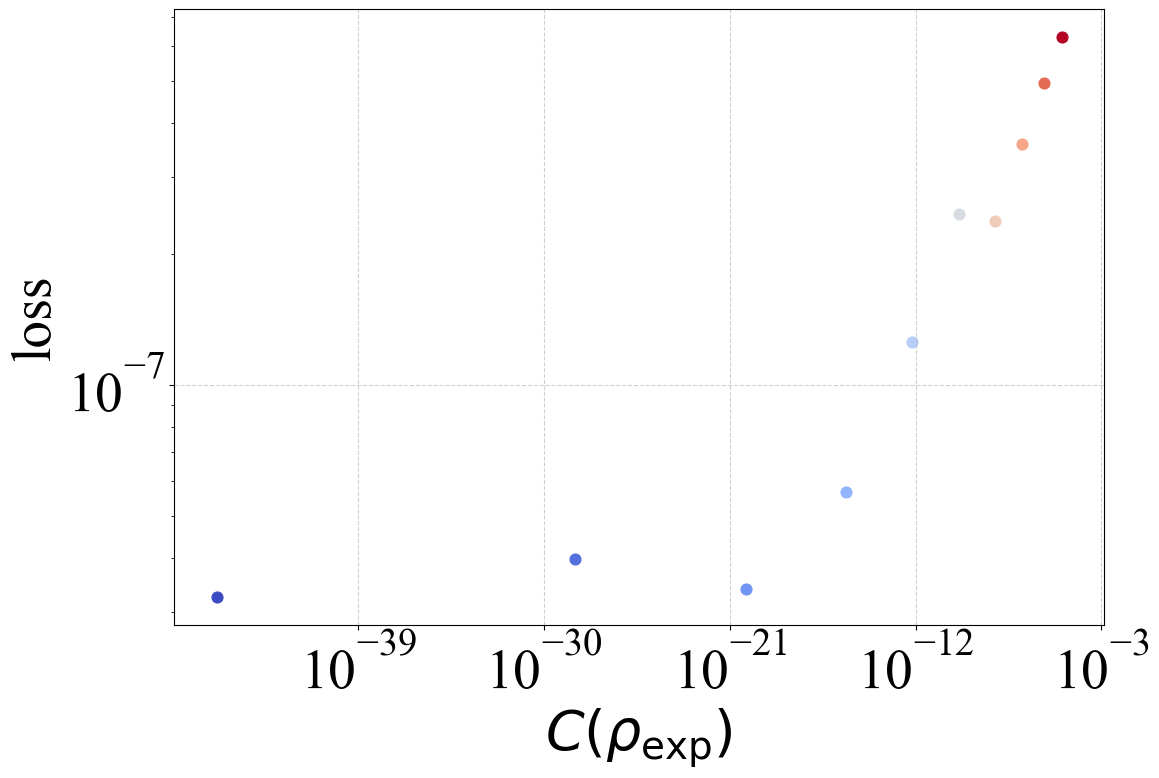

In [42]:

df = pd.read_pickle("data/TCN_exp_step3_data_clean.pkl")
df['m'] = df[m_key_dict['TCN']]
df = df[df['m'] == 64]

df['alpha'] = df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()
alpha_values = df.alpha.unique()
# --- Plotting loss vs C(m+1) for each memory function ---
fig, ax = plt.subplots(figsize=figsize)

# ax.set_title(f"{name} Memory", fontsize=font_size)
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm

for alpha in alpha_values:
    C_values = cumulative_function(memory_functions['Exponential'], alpha)
    df_alpha = df_min[df_min['alpha'] == alpha]
    m_plus_1 = df_alpha['m'] + 1
    C_m_plus_1 = C_values[m_plus_1]
    ax.scatter(C_m_plus_1, df_alpha[loss], color=cmap(norm(alpha)), label=f"α={alpha:.2f}", s=60)

ax.set_xlabel(r"$C(\rho_{\text{exp}})$", fontsize=font_size)
ax.set_ylabel('loss', fontsize=font_size)
ax.set_yscale('log')
ax.set_xscale('log')

ax.grid(True)
plt.savefig("figs/TCN_complexity1_exp.pdf", bbox_inches='tight')

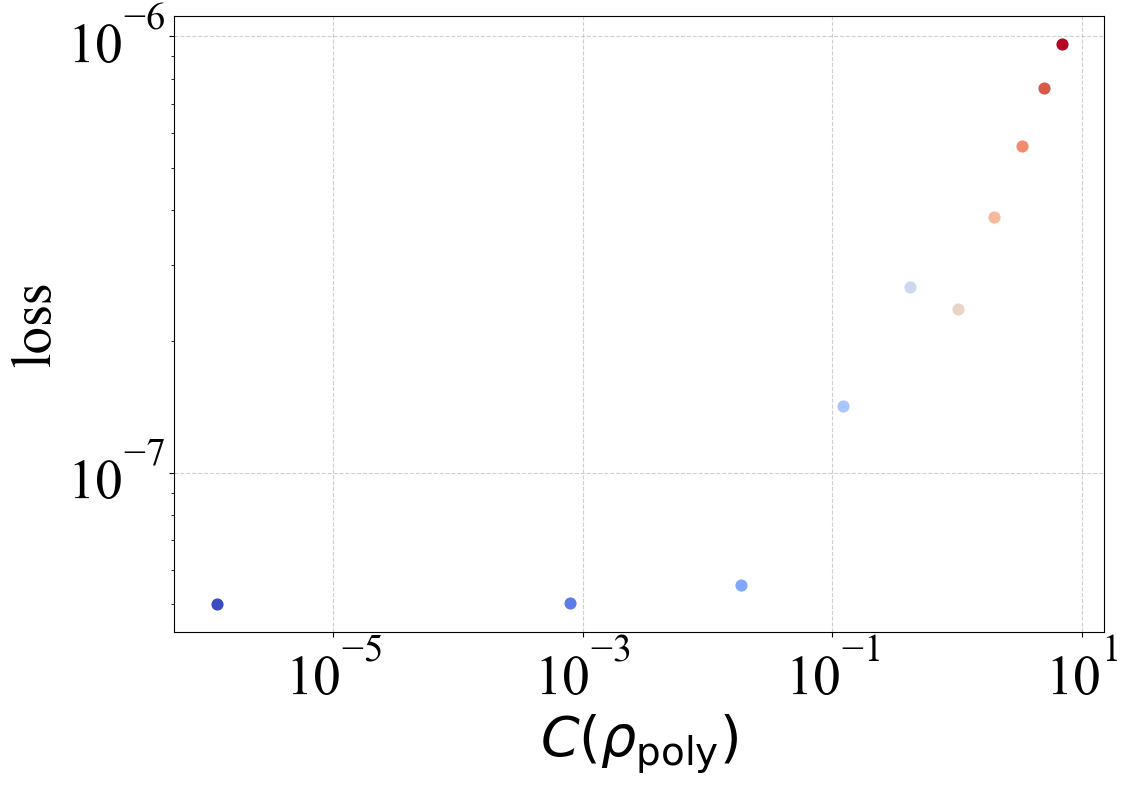

In [43]:

df = pd.read_pickle("data/TCN_poly_step3_data_clean.pkl")
df['m'] = df[m_key_dict['TCN']]
df = df[df['m'] == 64]

df['alpha'] = df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()
alpha_values = df.alpha.unique()

# --- Plotting loss vs C(m+1) for each memory function ---
fig, ax = plt.subplots(figsize=figsize)

# ax.set_title(f"{name} Memory", fontsize=font_size)
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm

for alpha in alpha_values:
    C_values = cumulative_function(memory_functions['Polynomial'], alpha)
    df_alpha = df_min[df_min['alpha'] == alpha]
    m_plus_1 = df_alpha['m'] + 1
    C_m_plus_1 = C_values[m_plus_1]
    ax.scatter(C_m_plus_1, df_alpha[loss], color=cmap(norm(alpha)), label=f"α={alpha:.2f}", s=60)

ax.set_xlabel(r"$C(\rho_{\text{poly}})$", fontsize=font_size)
ax.set_ylabel('loss', fontsize=font_size)
ax.set_yscale('log')
ax.set_xscale('log')

ax.grid(True)
plt.savefig("figs/TCN_complexity1_poly.pdf", bbox_inches='tight')

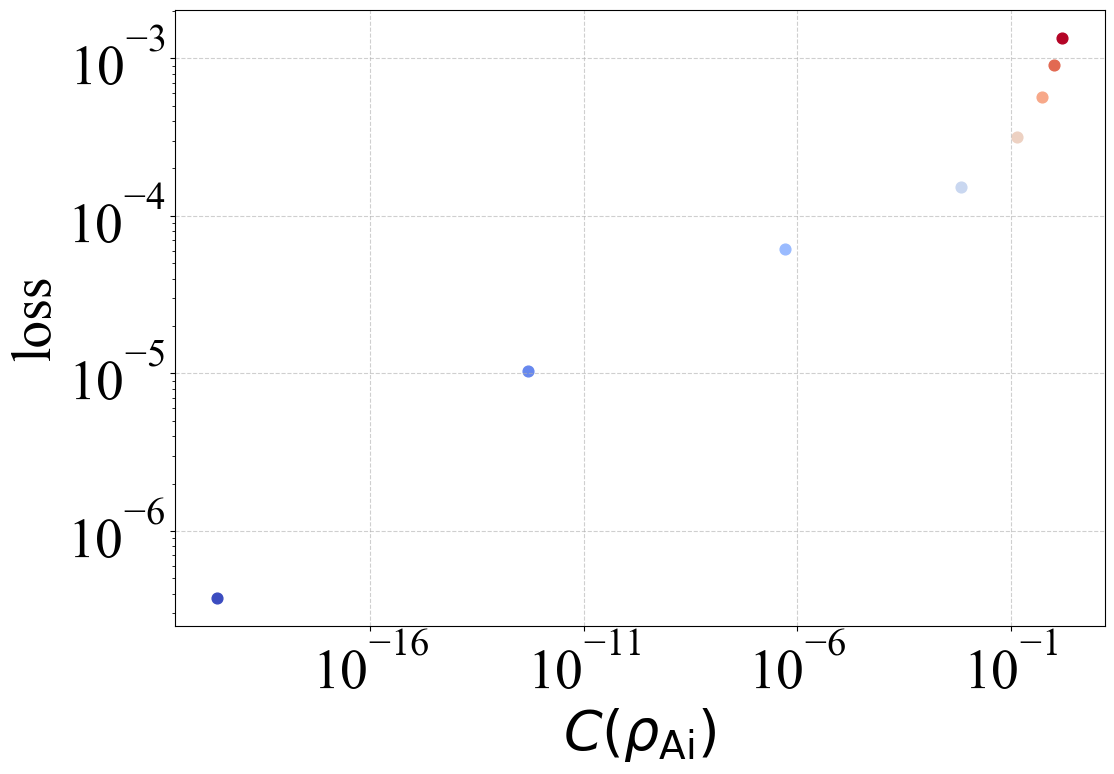

In [44]:

df = pd.read_pickle("data/TCN_airy_step3_data_clean.pkl")
df['m'] = df[m_key_dict['TCN']]
df = df[df['m'] == 64]

df['alpha'] = df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()
alpha_values = df.alpha.unique()
# --- Plotting loss vs C(m+1) for each memory function ---
fig, ax = plt.subplots(figsize=figsize)

# ax.set_title(f"{name} Memory", fontsize=font_size)
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm

for alpha in alpha_values:
    C_values = cumulative_function(memory_functions['Airy'], alpha)
    df_alpha = df_min[df_min['alpha'] == alpha]
    m_plus_1 = df_alpha['m'] + 1
    C_m_plus_1 = C_values[m_plus_1]
    ax.scatter(C_m_plus_1, df_alpha[loss], color=cmap(norm(alpha)), label=f"α={alpha:.2f}", s=60)

ax.set_xlabel("C(m+1)", fontsize=font_size)
ax.set_ylabel('loss', fontsize=font_size)
ax.set_yscale('log')
ax.set_xscale('log')

ax.grid(True)
ax.set_xlabel(r"$C(\rho_{\text{Ai}})$", fontsize=font_size)

plt.savefig("figs/TCN_complexity1_airy.pdf", bbox_inches='tight')

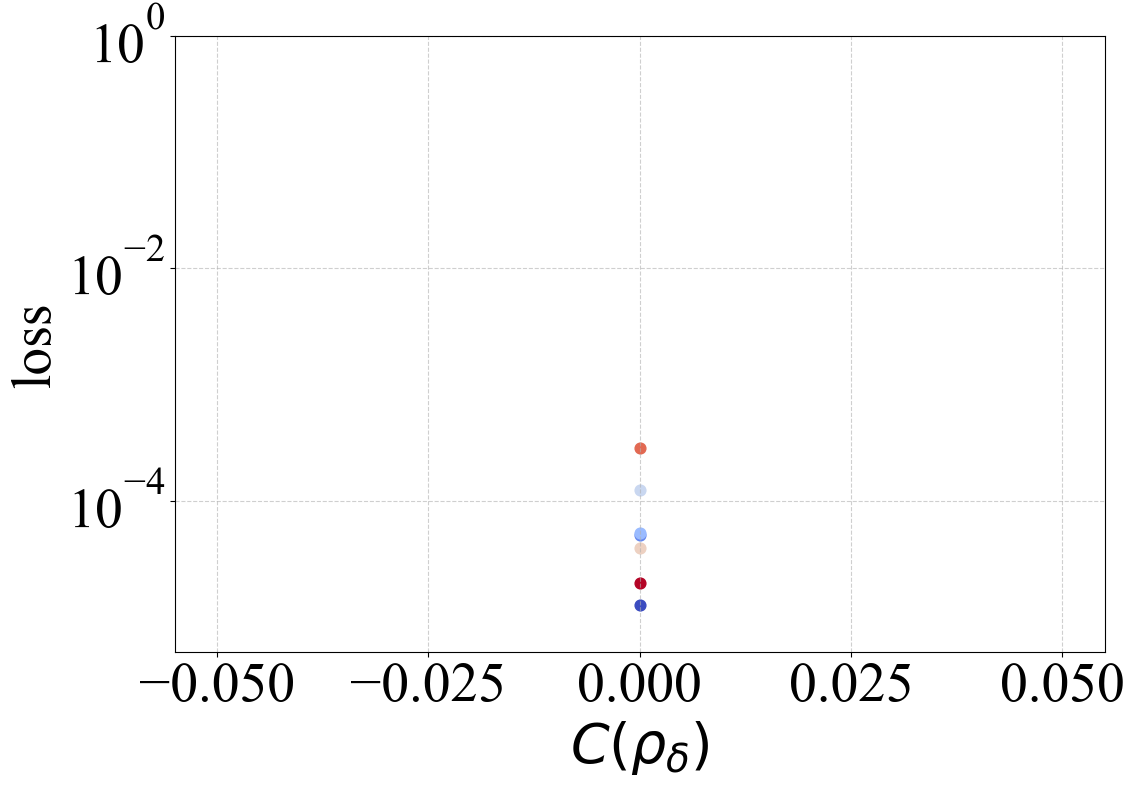

In [45]:

df = pd.read_pickle("data/TCN_impulse_step3_data_clean.pkl")
df['m'] = df[m_key_dict['TCN']]
df = df[df['m'] == df['m'].max()]

df['alpha'] = df['data.rho_param.alpha'] / df['data.rho_param.alpha'].max()
alpha_values = df.alpha.unique()
df_min = df.groupby(['m', 'alpha'], as_index=False)[loss].min()

# --- Plotting loss vs C(m+1) for each memory function ---
fig, ax = plt.subplots(figsize=figsize)

# ax.set_title(f"{name} Memory", fontsize=font_size)
norm = Normalize(vmin=min(alpha_values), vmax=max(alpha_values))
cmap = cm.coolwarm

for alpha in alpha_values:
    C_values = cumulative_function(memory_functions['Impulse'], alpha)
    df_alpha = df_min[df_min['alpha'] == alpha]
    m_plus_1 = df_alpha['m'] + 1
    C_m_plus_1 = C_values[m_plus_1]
    if df_alpha[loss].item() > 0.01:
        continue
    ax.scatter(C_m_plus_1, df_alpha[loss], color=cmap(norm(alpha)), label=f"α={alpha:.2f}", s=60)

ax.set_xlabel(r"$C(\rho_{\delta})$", fontsize=font_size)
ax.set_ylabel('loss', fontsize=font_size)
ax.set_yscale('log')
ax.grid(True)
ax.set_ylim(0.5*1e-5, 1)

plt.savefig("figs/TCN_complexity1_impulse.pdf", bbox_inches='tight')